# Travel Reimbursement Approval Agent

An LLM agent (LangChain + OpenRouter) that reads a travel expense claim, grounds itself in the company travel policy,
calls deterministic checking tools, and returns one of **APPROVE · PARTIAL_APPROVE · REJECT · MANUAL_REVIEW**
with amounts, missing documents, cited policy rules, a confidence score and a plain-English explanation.

```
Claim (JSON / CSV / form) → Intake (Pydantic) → LLM agent ⇄ tools → Guardrail → JSON result → Dashboard
```

## README

### 1. Setup
Requires **Python 3.12+**. With [uv](https://docs.astral.sh/uv/) (recommended):

```bash
uv sync                                   # creates .venv and installs everything from pyproject.toml / uv.lock
```

Or with pip:

```bash
pip install langchain langchain-openai pydantic pandas matplotlib ipywidgets ipykernel jupyter python-dotenv
```

### 2. Environment variables

| Variable | Required | Default | Purpose |
|---|---|---|---|
| `OPENROUTER_API_KEY` | **yes** | — | API key from https://openrouter.ai/keys |
| `OPENROUTER_MODEL` | **yes** | — | OpenRouter model id that supports tool calling, e.g. `openai/gpt-oss-120b` |

Put them in a `.env` file next to this notebook (see `.env.example`) or export them in your shell:

```bash
OPENROUTER_API_KEY=sk-or-...
OPENROUTER_MODEL=openai/gpt-oss-120b
```

The model is called through OpenRouter's OpenAI-compatible API (`https://openrouter.ai/api/v1`) with LangChain's
`ChatOpenAI`, so any OpenRouter model with tool-calling support can be swapped in by changing `OPENROUTER_MODEL`.

### 3. Run the demo
* **Interactive:** `uv run jupyter lab abhijit-pardeshi.ipynb` (or open it in VS Code and select the `.venv` kernel) → *Run All*.
* **Headless:** `uv run jupyter nbconvert --to notebook --execute --inplace abhijit-pardeshi.ipynb`


Use the interactive panel under **Dashboard** to re-run a sample claim or submit a new one through a form or pasted JSON.

### 4. Key design choices
* **Tools do the math, the LLM orchestrates and explains, a guardrail validates.** Every amount comes from
  deterministic Python tools, so numbers are exact and reproducible; the LLM decides which tools to call,
  combines their findings into a decision and writes the explanation.
* **Rule-ID grounding instead of vector RAG.** The policy has ~15 rules with stable `POL-*` ids, so a
  keyword/rule-id lookup tool returns the exact rule text — no embeddings, and citations are always real ids.
* **Fail safe to Manual Review.** A post-LLM guardrail forces `MANUAL_REVIEW` on hard triggers (missing receipt,
  premium cabin, > $2,000, late, conflicting data) and on any LLM/parsing failure — it never forces a decision.


## 1. Setup
Load `OPENROUTER_API_KEY` and `OPENROUTER_MODEL` from `.env` and create the chat model via OpenRouter's
OpenAI-compatible endpoint (temperature 0 for repeatable runs).

In [68]:
import json
import os
import re
import io
import csv
from datetime import date
from typing import Literal, Optional

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pydantic import BaseModel, ConfigDict, Field, field_validator, model_validator
from dotenv import find_dotenv, load_dotenv

from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langchain.agents.structured_output import ToolStrategy
from langchain_core.tools import tool
from langchain_core.messages import AIMessage, HumanMessage, ToolMessage

load_dotenv(find_dotenv(usecwd=True))  # reads .env from the notebook's folder (or a parent), if present

OPENROUTER_BASE_URL = "https://openrouter.ai/api/v1"
OPENROUTER_API_KEY = os.getenv("OPENROUTER_API_KEY")
OPENROUTER_MODEL = os.getenv("OPENROUTER_MODEL")
missing = [name for name, val in [("OPENROUTER_API_KEY", OPENROUTER_API_KEY),
                                  ("OPENROUTER_MODEL", OPENROUTER_MODEL)] if not val]
if missing:
    raise EnvironmentError(
        f"Missing {', '.join(missing)}. Add them to a .env file next to this notebook, e.g.\n"
        "  OPENROUTER_API_KEY=sk-or-...\n  OPENROUTER_MODEL=openai/gpt-oss-120b\n"
        "(see README above), or export them in your shell, then re-run."
    )

llm = ChatOpenAI(
    model=OPENROUTER_MODEL,
    api_key=OPENROUTER_API_KEY,
    base_url=OPENROUTER_BASE_URL,
    temperature=0,
    max_retries=4,   # the SDK backs off and retries on rate limits / transient errors
    timeout=120,
    default_headers={"X-Title": "Travel Reimbursement Agent (prototype)"},  # optional OpenRouter app label
)
pd.set_option("display.max_colwidth", 120)
print(f"LLM ready: OpenRouter / {OPENROUTER_MODEL}")

LLM ready: OpenRouter / openai/gpt-oss-120b


## 2. Policy
The policy text is parsed into `{rule_id: text}` so tools can return exact rule text and the
agent can cite stable ids. The small machine-readable tables below (limits, eligibility, approval matrix) are derived
directly from those rules.

In [69]:
POLICY_TEXT = """
## Appendix A — Travel Reimbursement Policy

1. Eligible & Ineligible Categories
POL-CAT-01 — Eligible categories — Reimbursable when incurred for a documented business purpose:
• Airfare (economy class only — see POL-AIR-01)
• Lodging (hotel room charges)
• Meals (subject to per-diem limits — see POL-PD-01)
• Ground transport (taxi, rideshare, train, rental car, parking)
• Conference / registration fees
POL-CAT-02 — Ineligible items — Never reimbursable; rejected (deducted in full):
• Alcohol and minibar charges
• Spa, gym, and personal entertainment
• In-room movies, personal shopping, gifts
• Traffic fines, penalties, and late fees
• Any personal (non-business) expense
2. Per-Diem & Category Limits
POL-PD-01 — Meals — Maximum $75 per day. Amounts above the daily cap are deducted; the rest is reimbursed.
POL-PD-02 — Lodging — Maximum $200 per night. Amounts above the nightly cap are deducted; the rest is reimbursed.
POL-PD-03 — Ground transport — Maximum $50 per day. Amounts above the cap are deducted.
POL-AIR-01 — Airfare class — Only economy class airfare is reimbursable. Business/first-class fares are a policy exception
and must be routed to Manual Review (not auto-deducted, because a pre-approval may exist).
3. Receipt Rules
POL-RCT-01 — Receipt required above $25 — Any single line item greater than $25 requires an attached, itemized receipt.
Airfare and lodging always require a receipt regardless of amount.
POL-RCT-02 — Missing receipt handling — If a receipt is missing for an item that requires one, the item is not silently rejected
— the claim is routed to Manual Review so the reviewer can request the receipt.
4. Approval Thresholds
Thresholds are evaluated on the total reimbursable amount (after per-diem deductions but before final
decision).
POL-APR-01 — Auto-approve tier — Total ≤ $500: may be auto-approved by the agent if fully compliant.
POL-APR-02 — Manager tier — Total > $500 and ≤ $2,000: eligible for approval, treated as approvable when fully compliant.
POL-APR-03 — Director / Manual-Review tier — Total > $2,000: exceeds the agent's auto-approval authority and must be
routed to Manual Review (director approval required), even if otherwise compliant.
5. Timeliness
POL-TIME-01 — Submission window — Claims must be submitted within 30 days of the expense date. Late claims are routed
to Manual Review.
Decision Guidance (how the rules combine)
Approve — every item eligible, all receipts present, all within per-diem, total within an approvable tier (POL-APR-01 / POL-APR-
02).
Partially Approve — the claim is valid but some amounts exceed per-diem caps; reimburse up to the cap and deduct the
excess.
Reject — the claimed items are ineligible (POL-CAT-02) with nothing reimbursable.
Manual Review — any ambiguity, policy exception, high value (POL-APR-03), missing required receipt (POL-RCT-02), or
conflicting information. Prefer Manual Review over forcing a decision.
"""

RULE_LINE_RE = re.compile(r"^(POL-[A-Z]+-\d{2})\s*—\s*(.*)")
RULE_ID_RE = re.compile(r"POL-[A-Z]+-\d{2}")


def parse_policy(text: str) -> dict[str, str]:
    """Split the policy into rules keyed by POL id (+ a DECISION-GUIDANCE entry).

    Section preambles (e.g. 'Thresholds are evaluated on ...') are attached to every rule in that section.
    """
    rules: dict[str, str] = {}
    notes: dict[str, str] = {}
    current, section_note, section_rules = None, "", []

    def append(key, line):
        sep = "" if rules[key].endswith("-") else " "  # re-join words hyphen-wrapped across lines
        rules[key] = (rules[key] + sep + line).strip()

    for raw in text.splitlines():
        line = raw.strip()
        if not line or line.startswith("##"):
            continue
        m = RULE_LINE_RE.match(line)
        if m:
            current = m.group(1)
            rules[current] = m.group(2)
            section_rules.append(current)
        elif re.match(r"^\d+\.\s", line):            # new numbered section
            current, section_note, section_rules = None, "", []
        elif line.startswith("Decision Guidance"):
            current, section_note, section_rules = "DECISION-GUIDANCE", "", []
            rules[current] = ""
        elif current:
            append(current, line)
        else:
            section_note = (section_note + " " + line).strip()
        for rid in section_rules:
            notes[rid] = section_note
    for rid, note in notes.items():
        if note:
            rules[rid] += f" (Section note: {note})"
    return rules


POLICY_RULES = parse_policy(POLICY_TEXT)
display(pd.DataFrame(POLICY_RULES.items(), columns=["rule_id", "text"]))

,rule_id,text
0,POL-CAT-01,Eligible categories — Reimbursable when incurred for a documented business purpose: • Airfare (economy class only — ...
1,POL-CAT-02,"Ineligible items — Never reimbursable; rejected (deducted in full): • Alcohol and minibar charges • Spa, gym, and pe..."
2,POL-PD-01,Meals — Maximum $75 per day. Amounts above the daily cap are deducted; the rest is reimbursed.
3,POL-PD-02,Lodging — Maximum $200 per night. Amounts above the nightly cap are deducted; the rest is reimbursed.
4,POL-PD-03,Ground transport — Maximum $50 per day. Amounts above the cap are deducted.
5,POL-AIR-01,Airfare class — Only economy class airfare is reimbursable. Business/first-class fares are a policy exception and mu...
6,POL-RCT-01,"Receipt required above $25 — Any single line item greater than $25 requires an attached, itemized receipt. Airfare a..."
7,POL-RCT-02,"Missing receipt handling — If a receipt is missing for an item that requires one, the item is not silently rejected ..."
8,POL-APR-01,Auto-approve tier — Total ≤ $500: may be auto-approved by the agent if fully compliant. (Section note: Thresholds ar...
9,POL-APR-02,"Manager tier — Total > $500 and ≤ $2,000: eligible for approval, treated as approvable when fully compliant. (Sectio..."


In [70]:
# ---- Category eligibility (POL-CAT-01 / POL-CAT-02) ----
ELIGIBLE_CATEGORIES = ["airfare", "lodging", "meals", "ground_transport", "conference_fees"]
INELIGIBLE_CATEGORIES = ["alcohol", "minibar", "spa", "gym", "entertainment", "in_room_movies",
                         "personal_shopping", "gifts", "fines", "penalties", "late_fees", "personal"]
# Ineligible items hidden inside an otherwise-eligible category (e.g. "dinner + wine")
INELIGIBLE_KEYWORDS_RE = re.compile(
    r"\b(alcohol|wine|beer|liquor|minibar|spa|gym|in-room movie|movie|gift|traffic fine|fine|penalty|late fee)s?\b",
    re.I,
)
CATEGORY_ALIASES = {
    "flight": "airfare", "air": "airfare", "hotel": "lodging", "accommodation": "lodging",
    "meal": "meals", "food": "meals", "dining": "meals",
    "taxi": "ground_transport", "rideshare": "ground_transport", "uber": "ground_transport",
    "train": "ground_transport", "rental_car": "ground_transport", "parking": "ground_transport",
    "ground": "ground_transport", "transport": "ground_transport",
    "conference": "conference_fees", "registration": "conference_fees", "conference_fee": "conference_fees",
}

# ---- Per-diem / category limits (POL-PD-01..03) ----
CATEGORY_LIMITS = {
    "meals":            {"cap": 75.0,  "unit": "day",   "rule": "POL-PD-01"},
    "lodging":          {"cap": 200.0, "unit": "night", "rule": "POL-PD-02"},
    "ground_transport": {"cap": 50.0,  "unit": "day",   "rule": "POL-PD-03"},
}

# ---- Receipt rules (POL-RCT-01 / 02) ----
RECEIPT_THRESHOLD = 25.0
ALWAYS_NEED_RECEIPT = {"airfare", "lodging"}

# ---- Approval matrix (POL-APR-01..03), evaluated on total reimbursable amount ----
APPROVAL_MATRIX = [
    {"max_amount": 500.0,        "tier": "AUTO_APPROVE",        "rule": "POL-APR-01", "agent_can_approve": True},
    {"max_amount": 2000.0,       "tier": "MANAGER",             "rule": "POL-APR-02", "agent_can_approve": True},
    {"max_amount": float("inf"), "tier": "DIRECTOR_MANUAL_REVIEW", "rule": "POL-APR-03", "agent_can_approve": False},
]

# ---- Timeliness (POL-TIME-01) ----
SUBMISSION_WINDOW_DAYS = 30

display(pd.DataFrame([{"category": c, **v} for c, v in CATEGORY_LIMITS.items()]).rename(
    columns={"cap": "cap_usd", "unit": "per"}))
display(pd.DataFrame(APPROVAL_MATRIX))
display(pd.DataFrame({"eligible (POL-CAT-01)": pd.Series(ELIGIBLE_CATEGORIES),
                      "ineligible (POL-CAT-02)": pd.Series(INELIGIBLE_CATEGORIES)}).fillna(""))

,category,cap_usd,per,rule
0,meals,75.0,day,POL-PD-01
1,lodging,200.0,night,POL-PD-02
2,ground_transport,50.0,day,POL-PD-03


,max_amount,tier,rule,agent_can_approve
0,500.0,AUTO_APPROVE,POL-APR-01,True
1,2000.0,MANAGER,POL-APR-02,True
2,inf,DIRECTOR_MANUAL_REVIEW,POL-APR-03,False


,eligible (POL-CAT-01),ineligible (POL-CAT-02)
0,airfare,alcohol
1,lodging,minibar
2,meals,spa
3,ground_transport,gym
4,conference_fees,entertainment
5,,in_room_movies
6,,personal_shopping
7,,gifts
8,,fines
9,,penalties


## 3. Sample Claims

Claims are validated into Pydantic models. Intake supports **JSON** (`load_claims_from_json`), **CSV**
(`load_claims_from_csv`) and the **form / pasted JSON** in the Dashboard panel.

In [71]:
SAMPLE_CLAIMS_JSON = """
[
  {"claim_id": "CLM-001", "employee": "A. Rivera", "purpose": "Attend 2-day industry conference (business)",
   "trip_start": "2026-06-10", "trip_end": "2026-06-12", "submitted": "2026-06-20",
   "items": [
     {"category": "airfare",         "description": "Round-trip economy airfare", "amount": 420.00, "receipt_attached": true},
     {"category": "lodging",         "description": "Hotel, 2 nights @ $180",     "amount": 360.00, "receipt_attached": true},
     {"category": "meals",           "description": "Meals, 3 days @ ~$60/day",   "amount": 180.00, "receipt_attached": true},
     {"category": "conference_fees", "description": "Conference registration",    "amount": 150.00, "receipt_attached": true}
   ]},
  {"claim_id": "CLM-002", "employee": "B. Osei", "purpose": "Weekend hotel stay",
   "trip_start": "2026-06-14", "trip_end": "2026-06-15", "submitted": "2026-06-25",
   "items": [
     {"category": "spa",     "description": "Hotel spa package", "amount": 300.00, "receipt_attached": true},
     {"category": "minibar", "description": "In-room minibar",   "amount": 80.00,  "receipt_attached": true}
   ]},
  {"claim_id": "CLM-003", "employee": "C. Nakamura", "purpose": "Client site visit (business)",
   "trip_start": "2026-06-08", "trip_end": "2026-06-10", "submitted": "2026-06-22",
   "items": [
     {"category": "airfare", "description": "Round-trip economy airfare", "amount": 300.00, "receipt_attached": true},
     {"category": "lodging", "description": "Hotel, 2 nights @ $250",     "amount": 500.00, "receipt_attached": true},
     {"category": "meals",   "description": "Meals, 2 days @ $70/day",    "amount": 140.00, "receipt_attached": true}
   ]},
  {"claim_id": "CLM-004", "employee": "D. Fischer", "purpose": "International vendor negotiation (business)",
   "trip_start": "2026-06-16", "trip_end": "2026-06-18", "submitted": "2026-06-28",
   "items": [
     {"category": "airfare", "description": "Business-class international airfare", "amount": 2400.00, "receipt_attached": true},
     {"category": "lodging", "description": "Hotel, 3 nights",                      "amount": 600.00,  "receipt_attached": false}
   ]},
  {"claim_id": "CLM-005", "employee": "E. Haddad", "purpose": "Client dinner / business development",
   "trip_start": "2026-06-11", "trip_end": "2026-06-11", "submitted": "2026-06-24",
   "items": [
     {"category": "meals", "description": "Client dinner for 4 (business development)", "amount": 220.00, "receipt_attached": false}
   ]}
]
"""


class LineItem(BaseModel):
    category: str
    description: str
    amount: float = Field(ge=0)
    receipt_attached: bool

    @field_validator("category")
    @classmethod
    def normalise_category(cls, v: str) -> str:
        key = re.sub(r"[\s\-/]+", "_", v.strip().lower())
        return CATEGORY_ALIASES.get(key, key)


class Claim(BaseModel):
    claim_id: str
    employee: str
    purpose: str
    trip_start: date
    trip_end: date
    submitted: date
    currency: str = "USD"
    items: list[LineItem] = Field(min_length=1)

    @model_validator(mode="after")
    def check_dates(self):
        if self.trip_end < self.trip_start:
            raise ValueError("trip_end is before trip_start")
        return self

    @property
    def total_claimed(self) -> float:
        return round(sum(i.amount for i in self.items), 2)


def load_claims_from_json(source: str) -> list[Claim]:
    """Accepts a JSON string (one claim object or a list of them)."""
    data = json.loads(source)
    data = data if isinstance(data, list) else [data]
    return [Claim.model_validate(d) for d in data]


CSV_COLUMNS = ["claim_id", "employee", "purpose", "trip_start", "trip_end", "submitted",
               "category", "description", "amount", "receipt_attached"]


def claims_to_csv(claims: list[Claim]) -> str:
    buf = io.StringIO()
    w = csv.DictWriter(buf, fieldnames=CSV_COLUMNS)
    w.writeheader()
    for c in claims:
        for i in c.items:
            w.writerow({"claim_id": c.claim_id, "employee": c.employee, "purpose": c.purpose,
                        "trip_start": c.trip_start, "trip_end": c.trip_end, "submitted": c.submitted,
                        "category": i.category, "description": i.description, "amount": i.amount,
                        "receipt_attached": "Yes" if i.receipt_attached else "No"})
    return buf.getvalue()


def load_claims_from_csv(source: str) -> list[Claim]:
    """One row per line item; rows sharing a claim_id are grouped into one claim."""
    grouped: dict[str, dict] = {}
    for row in csv.DictReader(io.StringIO(source)):
        c = grouped.setdefault(row["claim_id"], {k: row[k] for k in CSV_COLUMNS[:6]} | {"items": []})
        c["items"].append({"category": row["category"], "description": row["description"],
                           "amount": float(row["amount"]),
                           "receipt_attached": row["receipt_attached"].strip().lower() in ("yes", "true", "1", "y")})
    return [Claim.model_validate(c) for c in grouped.values()]


CLAIMS = load_claims_from_json(SAMPLE_CLAIMS_JSON)
CLAIM_REGISTRY: dict[str, Claim] = {c.claim_id: c for c in CLAIMS}

# CSV intake round-trip: same claims in, same claims out
assert load_claims_from_csv(claims_to_csv(CLAIMS)) == CLAIMS
print("CSV intake round-trip OK\n")

display(pd.DataFrame([{"claim_id": c.claim_id, "employee": c.employee, "purpose": c.purpose,
                       "trip": f"{c.trip_start} → {c.trip_end}", "submitted": c.submitted,
                       "items": len(c.items), "total_claimed": c.total_claimed} for c in CLAIMS]))

CSV intake round-trip OK



,claim_id,employee,purpose,trip,submitted,items,total_claimed
0,CLM-001,A. Rivera,Attend 2-day industry conference (business),2026-06-10 → 2026-06-12,2026-06-20,4,1110.0
1,CLM-002,B. Osei,Weekend hotel stay,2026-06-14 → 2026-06-15,2026-06-25,2,380.0
2,CLM-003,C. Nakamura,Client site visit (business),2026-06-08 → 2026-06-10,2026-06-22,3,940.0
3,CLM-004,D. Fischer,International vendor negotiation (business),2026-06-16 → 2026-06-18,2026-06-28,2,3000.0
4,CLM-005,E. Haddad,Client dinner / business development,2026-06-11 → 2026-06-11,2026-06-24,1,220.0


## 4. Tools
Each check is a **deterministic Python function** (also reused by the guardrail), exposed to the LLM as a
LangChain `@tool`. Tools return JSON with amounts, rule ids and flags so the LLM never has to do arithmetic.

| Tool | Policy rules | What it returns |
|---|---|---|
| `lookup_policy(query)` | all | Exact rule text for ids / keywords (context grounding) |
| `check_eligibility(claim_id)` | POL-CAT-01/02 | Eligible / ineligible / unknown per line |
| `check_per_diem_limits(claim_id)` | POL-PD-01/02/03, POL-AIR-01 | Allowed, deducted, pending-review amounts per line + conflict flags |
| `check_receipts(claim_id)` | POL-RCT-01/02 | Which lines need a receipt, `missing_docs` |
| `check_timeliness(claim_id)` | POL-TIME-01 | Days to submission, within window? |
| `check_approval_threshold(amount)` | POL-APR-01/02/03 | Approval tier for the reimbursable total |

In [72]:
# ----------------------------------------------------------------- policy lookup (grounding)
KEYWORD_RULES = {
    "airfare": ["POL-CAT-01", "POL-AIR-01", "POL-RCT-01"], "flight": ["POL-CAT-01", "POL-AIR-01", "POL-RCT-01"],
    "business class": ["POL-AIR-01"], "business-class": ["POL-AIR-01"], "first class": ["POL-AIR-01"],
    "economy": ["POL-AIR-01"], "cabin": ["POL-AIR-01"],
    "lodging": ["POL-CAT-01", "POL-PD-02", "POL-RCT-01"], "hotel": ["POL-CAT-01", "POL-PD-02", "POL-RCT-01"],
    "meal": ["POL-CAT-01", "POL-PD-01"], "dinner": ["POL-CAT-01", "POL-PD-01"],
    "per diem": ["POL-PD-01", "POL-PD-02", "POL-PD-03"], "per-diem": ["POL-PD-01", "POL-PD-02", "POL-PD-03"],
    "cap": ["POL-PD-01", "POL-PD-02", "POL-PD-03"], "limit": ["POL-PD-01", "POL-PD-02", "POL-PD-03"],
    "ground": ["POL-CAT-01", "POL-PD-03"], "taxi": ["POL-CAT-01", "POL-PD-03"],
    "transport": ["POL-CAT-01", "POL-PD-03"], "conference": ["POL-CAT-01"], "eligib": ["POL-CAT-01", "POL-CAT-02"],
    "spa": ["POL-CAT-02"], "minibar": ["POL-CAT-02"], "alcohol": ["POL-CAT-02"], "gym": ["POL-CAT-02"],
    "gift": ["POL-CAT-02"], "fine": ["POL-CAT-02"], "personal": ["POL-CAT-02"], "ineligible": ["POL-CAT-02"],
    "receipt": ["POL-RCT-01", "POL-RCT-02"], "missing": ["POL-RCT-02"],
    "approval": ["POL-APR-01", "POL-APR-02", "POL-APR-03"], "threshold": ["POL-APR-01", "POL-APR-02", "POL-APR-03"],
    "tier": ["POL-APR-01", "POL-APR-02", "POL-APR-03"], "director": ["POL-APR-03"], "manager": ["POL-APR-02"],
    "late": ["POL-TIME-01"], "submission": ["POL-TIME-01"], "timeliness": ["POL-TIME-01"], "deadline": ["POL-TIME-01"],
    "decision": ["DECISION-GUIDANCE"], "manual review": ["DECISION-GUIDANCE"], "partial": ["DECISION-GUIDANCE"],
    "reject": ["DECISION-GUIDANCE"], "ambigu": ["DECISION-GUIDANCE"],
}


def policy_search(query: str, max_results: int = 8) -> list[dict]:
    q = query.lower()
    ids: list[str] = []
    for rid in RULE_ID_RE.findall(query.upper()):          # explicit rule ids first
        if rid in POLICY_RULES and rid not in ids:
            ids.append(rid)
    for kw, rids in KEYWORD_RULES.items():                  # then keyword / category matches
        if kw in q:
            ids += [r for r in rids if r not in ids]
    if not ids:                                             # fallback: plain word overlap
        words = {w for w in re.findall(r"[a-z]{4,}", q)}
        scored = sorted(((sum(w in t.lower() for w in words), r) for r, t in POLICY_RULES.items()), reverse=True)
        ids = [r for s, r in scored[:3] if s > 0]
    return [{"rule_id": r, "text": POLICY_RULES[r]} for r in ids[:max_results]]


# ----------------------------------------------------------------- deterministic checks
PREMIUM_CABIN_RE = re.compile(r"\b(business|first)[\s-]*class\b", re.I)
GROUP_MEAL_RE = re.compile(r"\bfor\s+(\d+)\b", re.I)


def classify_line(item: LineItem) -> tuple[str, str, str]:
    """Returns (status, rule_id, reason) with status in eligible | ineligible | unknown."""
    if item.category in INELIGIBLE_CATEGORIES:
        return "ineligible", "POL-CAT-02", f"category '{item.category}' is never reimbursable"
    kw = INELIGIBLE_KEYWORDS_RE.search(item.description)
    if kw:
        return "ineligible", "POL-CAT-02", f"description mentions ineligible item '{kw.group(0)}'"
    if item.category in ELIGIBLE_CATEGORIES:
        return "eligible", "POL-CAT-01", f"'{item.category}' is an eligible category"
    return "unknown", "POL-CAT-01", f"category '{item.category}' is not listed in the policy"


def eligibility_facts(claim: Claim) -> dict:
    lines = []
    for n, item in enumerate(claim.items, 1):
        status, rule, reason = classify_line(item)
        lines.append({"line": n, "category": item.category, "description": item.description,
                      "amount": item.amount, "status": status, "rule": rule, "reason": reason})
    return {"claim_id": claim.claim_id, "purpose": claim.purpose,
            "business_purpose_stated": "business" in claim.purpose.lower(),
            "lines": lines,
            "all_eligible": all(l["status"] == "eligible" for l in lines),
            "all_ineligible": all(l["status"] == "ineligible" for l in lines)}


def _stated_quantity(description: str, unit: str) -> Optional[int]:
    m = re.search(rf"(\d+)\s*{unit}s?\b", description, re.I)
    return int(m.group(1)) if m else None


def _trip_quantity(claim: Claim, unit: str) -> int:
    span = (claim.trip_end - claim.trip_start).days
    return max(span, 1) if unit == "night" else span + 1


def per_diem_facts(claim: Claim) -> dict:
    lines, flags = [], []
    for n, item in enumerate(claim.items, 1):
        status, rule, reason = classify_line(item)
        row = {"line": n, "category": item.category, "description": item.description, "claimed": item.amount,
               "allowed": 0.0, "deducted": 0.0, "pending_review": 0.0, "rule": rule, "note": ""}
        if status == "ineligible":
            row.update(deducted=item.amount, note=f"Ineligible: {reason} (deducted in full)")
        elif status == "unknown":
            row.update(pending_review=item.amount, note=f"Unknown category: {reason}")
            flags.append({"type": "unknown_category", "rule": "POL-CAT-01",
                          "message": f"Line {n}: {reason}; needs human classification"})
        elif item.category == "airfare" and PREMIUM_CABIN_RE.search(item.description):
            row.update(pending_review=item.amount, rule="POL-AIR-01",
                       note="Premium-cabin airfare is a policy exception: route to Manual Review, not auto-deducted")
            flags.append({"type": "premium_cabin", "rule": "POL-AIR-01",
                          "message": f"Line {n}: business/first-class airfare (${item.amount:,.2f}) is a policy exception"})
        elif item.category in CATEGORY_LIMITS:
            lim = CATEGORY_LIMITS[item.category]
            unit = lim["unit"]
            stated, trip = _stated_quantity(item.description, unit), _trip_quantity(claim, unit)
            qty = stated or trip
            cap_total = lim["cap"] * qty
            allowed = min(item.amount, cap_total)
            row.update(allowed=round(allowed, 2), deducted=round(item.amount - allowed, 2), rule=lim["rule"],
                       units=qty, unit=unit, cap_per_unit=lim["cap"], cap_total=cap_total,
                       claimed_per_unit=round(item.amount / qty, 2),
                       note=(f"${item.amount / qty:,.2f}/{unit} over {qty} {unit}(s) vs cap ${lim['cap']:,.0f}/{unit}"
                             + (f" → ${item.amount - allowed:,.2f} above cap deducted" if item.amount > allowed
                                else " → within cap")))
            if stated and stated > trip:
                flags.append({"type": "quantity_conflict", "rule": lim["rule"],
                              "message": f"Line {n}: claims {stated} {unit}s but trip dates "
                                         f"{claim.trip_start}→{claim.trip_end} cover only {trip}"})
            if item.category == "meals" and (g := GROUP_MEAL_RE.search(item.description)) and int(g.group(1)) > 1:
                flags.append({"type": "group_meal", "rule": "POL-PD-01",
                              "message": f"Line {n}: meal for {g.group(1)} people; the $75/day per-diem is per "
                                         "employee and the policy does not cover client hosting"})
        else:  # eligible, uncapped (economy airfare, conference fees)
            row.update(allowed=item.amount, note="Eligible, no per-diem cap")
        lines.append(row)
    totals = {k: round(sum(l[k] for l in lines), 2) for k in ("claimed", "allowed", "deducted", "pending_review")}
    return {"claim_id": claim.claim_id, "lines": lines, "totals": totals, "flags": flags,
            "reimbursable_for_threshold": round(totals["allowed"] + totals["pending_review"], 2)}


def receipt_facts(claim: Claim) -> dict:
    lines, missing = [], []
    for n, item in enumerate(claim.items, 1):
        required = item.amount > RECEIPT_THRESHOLD or item.category in ALWAYS_NEED_RECEIPT
        why = ("airfare/lodging always need a receipt" if item.category in ALWAYS_NEED_RECEIPT
               else f"amount > ${RECEIPT_THRESHOLD:.0f}" if required else "not required")
        ok = item.receipt_attached or not required
        lines.append({"line": n, "category": item.category, "amount": item.amount, "receipt_required": required,
                      "receipt_attached": item.receipt_attached, "reason": why, "ok": ok})
        if not ok:
            missing.append(f"Itemized receipt for line {n} ({item.category}: {item.description}, ${item.amount:,.2f})")
    return {"claim_id": claim.claim_id, "lines": lines, "missing_docs": missing,
            "all_receipts_present": not missing,
            "rule": "POL-RCT-02" if missing else "POL-RCT-01"}


def threshold_facts(amount: float) -> dict:
    row = next(r for r in APPROVAL_MATRIX if amount <= r["max_amount"])
    return {"reimbursable_amount": round(amount, 2), "tier": row["tier"], "rule": row["rule"],
            "agent_can_approve": row["agent_can_approve"]}


def timeliness_facts(claim: Claim) -> dict:
    # Line items carry no individual dates, so the trip start is used as the (earliest, most conservative) expense date.
    days = (claim.submitted - claim.trip_start).days
    flags = []
    if claim.submitted < claim.trip_end:
        flags.append({"type": "date_conflict", "rule": "POL-TIME-01",
                      "message": f"Submitted {claim.submitted} before the trip ended {claim.trip_end}"})
    return {"claim_id": claim.claim_id, "earliest_expense_date": str(claim.trip_start),
            "submitted": str(claim.submitted), "days_after_expense": days,
            "window_days": SUBMISSION_WINDOW_DAYS, "within_window": 0 <= days <= SUBMISSION_WINDOW_DAYS,
            "rule": "POL-TIME-01", "flags": flags}


# ----------------------------------------------------------------- LangChain tool wrappers
def _get(claim_id: str) -> Optional[Claim]:
    return CLAIM_REGISTRY.get(claim_id.strip().upper())


def _dump(obj) -> str:
    return json.dumps(obj, separators=(",", ":"))  # compact JSON keeps the agent's context (and token use) small


def _unknown(claim_id):
    return json.dumps({"error": f"Unknown claim_id '{claim_id}'. Known: {list(CLAIM_REGISTRY)}"})


@tool
def lookup_policy(query: str) -> str:
    """Look up the travel reimbursement policy. Pass rule ids (e.g. 'POL-PD-02') and/or keywords such as
    expense categories or issues (e.g. 'lodging cap', 'missing receipt', 'business class airfare', 'approval tier').
    Returns the exact rule text with the rule ids you may cite."""
    hits = policy_search(query)
    return _dump({"query": query, "rules": hits} if hits else {"query": query, "rules": [],
                      "hint": "No match. Try a category name or a rule id like POL-CAT-01."})


@tool
def check_eligibility(claim_id: str) -> str:
    """Check every line item of the claim against the eligible / ineligible category lists (POL-CAT-01, POL-CAT-02)."""
    c = _get(claim_id)
    return _dump(eligibility_facts(c)) if c else _unknown(claim_id)


@tool
def check_per_diem_limits(claim_id: str) -> str:
    """Apply per-diem caps (meals $75/day, lodging $200/night, ground $50/day) and the economy-only airfare rule.
    Returns allowed, deducted and pending_review amounts per line and in total, plus flags for policy exceptions
    or conflicting information. Use these numbers as-is; do not recompute them."""
    c = _get(claim_id)
    return _dump(per_diem_facts(c)) if c else _unknown(claim_id)


@tool
def check_receipts(claim_id: str) -> str:
    """Check receipt completeness: any line > $25, and all airfare/lodging, needs an itemized receipt (POL-RCT-01).
    Returns missing_docs; a missing required receipt means Manual Review (POL-RCT-02)."""
    c = _get(claim_id)
    return _dump(receipt_facts(c)) if c else _unknown(claim_id)


@tool
def check_timeliness(claim_id: str) -> str:
    """Check the claim was submitted within 30 days of the expense date (POL-TIME-01)."""
    c = _get(claim_id)
    return _dump(timeliness_facts(c)) if c else _unknown(claim_id)


@tool
def check_approval_threshold(reimbursable_amount: float) -> str:
    """Return the approval tier (POL-APR-01/02/03) for a total reimbursable amount. Pass the
    'reimbursable_for_threshold' value from check_per_diem_limits (allowed + pending_review)."""
    return _dump(threshold_facts(float(reimbursable_amount)))


TOOLS = [lookup_policy, check_eligibility, check_per_diem_limits, check_receipts, check_timeliness,
         check_approval_threshold]
TOOL_NAMES = [t.name for t in TOOLS]

# Quick smoke test of the deterministic layer (no LLM involved)
print(json.dumps(per_diem_facts(CLAIM_REGISTRY["CLM-003"])["totals"]), "<- CLM-003 per-diem totals")
print(lookup_policy.invoke({"query": "lodging cap"})[:200], "...")

{"claimed": 940.0, "allowed": 840.0, "deducted": 100.0, "pending_review": 0.0} <- CLM-003 per-diem totals
{"query":"lodging cap","rules":[{"rule_id":"POL-CAT-01","text":"Eligible categories \u2014 Reimbursable when incurred for a documented business purpose: \u2022 Airfare (economy class only \u2014 see P ...


## 5. The agent
`create_agent` builds a tool-calling (ReAct-style) loop: the LLM reads the claim, **decides which tools to call
and in what order**, reads their JSON results, and finally returns a structured `ClaimDecision`
(enforced with `ToolStrategy`). The system prompt tells it to ground itself in the policy first, never do its own
arithmetic, and prefer Manual Review whenever information is missing, conflicting or ambiguous.

In [73]:
Decision = Literal["APPROVE", "PARTIAL_APPROVE", "REJECT", "MANUAL_REVIEW"]


class ClaimDecision(BaseModel):
    """The agent's decision for one claim."""
    decision: Decision
    approved_amount: float = Field(description="USD to reimburse; 0 for MANUAL_REVIEW")
    deducted_amount: float = Field(description="USD deducted; 0 for MANUAL_REVIEW")
    policy_refs: list[str] = Field(description="POL-* rule ids supporting the decision")
    confidence: float = Field(ge=0, le=1)
    explanation: str = Field(description="2-4 sentences for a human reviewer, citing rule ids")


SYSTEM_PROMPT = """You are a Travel Reimbursement Approval Agent. You evaluate ONE expense claim against the
company travel policy and decide APPROVE, PARTIAL_APPROVE, REJECT or MANUAL_REVIEW.

How to work:
1. Ground yourself first: call lookup_policy for the expense categories and issues in this claim.
   Only cite rule ids that lookup_policy returned.
2. Gather facts with the check tools (pass the claim_id): check_eligibility, check_per_diem_limits,
   check_receipts, check_timeliness, then check_approval_threshold with 'reimbursable_for_threshold'
   from check_per_diem_limits. Skip a tool only if it clearly cannot matter.
   then check_approval_threshold, then give your final answer. Always call check_approval_threshold unless
   everything is ineligible, and quote the exact tier it returns - never infer the tier yourself.
3. Never do your own arithmetic for amounts - use the totals returned by check_per_diem_limits.
4. Decide, following the policy's decision guidance:
   - APPROVE: every item eligible, required receipts present, within caps, approvable tier (<= $2,000), on time.
   - PARTIAL_APPROVE: a valid claim where some amounts exceed caps or some items are ineligible;
     reimburse the allowed amount and deduct the rest.
   - REJECT: everything claimed is ineligible; nothing is reimbursable.
   - If totals.deducted > 0 the decision can NOT be APPROVE.
   - MANUAL_REVIEW: a missing required receipt, premium-cabin airfare, total > $2,000, late submission,
     any flag from the tools, conflicting or ambiguous information, or anything you are unsure about.
     When in doubt choose MANUAL_REVIEW - never force a decision.
5. Amounts: for APPROVE / PARTIAL_APPROVE / REJECT use approved_amount = totals.allowed and
   deducted_amount = totals.deducted. For MANUAL_REVIEW set both to 0 (nothing is decided yet) and state the
   provisional figures in the explanation.
6. confidence: 0.9-1.0 when the rules are clear-cut, 0.6-0.8 with some ambiguity, below 0.6 if facts conflict.
7. explanation: 2-4 plain sentences a reviewer can act on, citing rule ids and mentioning every flag the tools raised.
"""

agent = create_agent(model=llm, tools=TOOLS, system_prompt=SYSTEM_PROMPT,
                     response_format=ToolStrategy(ClaimDecision))


def build_user_message(claim: Claim) -> str:
    return (f"Evaluate claim {claim.claim_id}. Currency: {claim.currency}. Claim data:\n"
            f"{claim.model_dump_json(indent=2)}\n"
            f"Total claimed: ${claim.total_claimed:,.2f}")


def run_agent(claim: Claim, attempts: int = 3):
    """Run the agent loop. Returns (ClaimDecision | None, tool_trace, error | None)."""
    error = None
    for _ in range(attempts):
        try:
            out = agent.invoke({"messages": [HumanMessage(build_user_message(claim))]},
                               config={"recursion_limit": 30})
            return out.get("structured_response"), extract_tool_trace(out["messages"]), None
        except Exception as e:  # network / rate-limit / malformed tool call (e.g. a hallucinated tool name) -> retry, then fail safe
            error = f"{type(e).__name__}: {str(e)[:200]}"
    return None, [], error


def extract_tool_trace(messages) -> list[dict]:
    """The tools the agent actually called (in order), taken from the message history - not self-reported."""
    executed = {m.tool_call_id for m in messages if isinstance(m, ToolMessage)}
    return [{"tool": tc["name"], "args": tc["args"]}
            for m in messages if isinstance(m, AIMessage)
            for tc in m.tool_calls if tc["name"] in TOOL_NAMES and tc["id"] in executed]

## 6. Guardrail / output validator
The LLM's answer is checked against the same deterministic facts before it is accepted:

* **Hard triggers force `MANUAL_REVIEW`**: missing required receipt (POL-RCT-02), premium cabin (POL-AIR-01),
  total > $2,000 (POL-APR-03), late submission (POL-TIME-01), conflicting quantities/dates, unknown category,
  group meal ambiguity. The LLM may escalate to Manual Review on its own, but can never de-escalate past a trigger.
* **Amounts come from the tools**; if the LLM's numbers differ they are corrected (and noted).
* **Policy refs are filtered** to real `POL-*` ids; refs required by the triggers/deductions are added; a wrong
  approval tier quoted in the explanation is flagged.
* **`tools_used`** is taken from the actual tool-call trace.
* **LLM failure → `MANUAL_REVIEW`** with low confidence, so the pipeline never crashes or forces a decision.
* Output is validated against a strict schema (exactly the 9 required keys).

In [74]:
RESULT_KEYS = ["claim_id", "decision", "approved_amount", "deducted_amount", "missing_docs",
               "policy_refs", "confidence", "explanation", "tools_used"]


class ClaimResult(BaseModel):
    model_config = ConfigDict(extra="forbid")
    claim_id: str
    decision: Decision
    approved_amount: float = Field(ge=0)
    deducted_amount: float = Field(ge=0)
    missing_docs: list[str]
    policy_refs: list[str]
    confidence: float = Field(ge=0, le=1)
    explanation: str
    tools_used: list[str]


def compute_facts(claim: Claim) -> dict:
    pdf = per_diem_facts(claim)
    return {"per_diem": pdf, "receipts": receipt_facts(claim), "timeliness": timeliness_facts(claim),
            "threshold": threshold_facts(pdf["reimbursable_for_threshold"])}


def hard_triggers(f: dict) -> list[tuple[str, str]]:
    t = []
    if f["receipts"]["missing_docs"]:
        t.append((f"{len(f['receipts']['missing_docs'])} required receipt(s) missing", "POL-RCT-02"))
    t += [(fl["message"], fl["rule"]) for fl in f["per_diem"]["flags"]]
    if not f["threshold"]["agent_can_approve"]:
        t.append((f"reimbursable total ${f['threshold']['reimbursable_amount']:,.2f} exceeds the $2,000 "
                  "auto-approval authority", "POL-APR-03"))
    if not f["timeliness"]["within_window"]:
        t.append((f"submitted {f['timeliness']['days_after_expense']} days after expense (> 30)", "POL-TIME-01"))
    t += [(fl["message"], fl["rule"]) for fl in f["timeliness"]["flags"]]
    return t


def baseline_decision(f: dict, triggers) -> str:
    """What the rules alone would decide - used to sanity-check the LLM."""
    if triggers:
        return "MANUAL_REVIEW"
    tot = f["per_diem"]["totals"]
    if tot["allowed"] == 0 and tot["deducted"] > 0:
        return "REJECT"
    return "PARTIAL_APPROVE" if tot["deducted"] > 0 else "APPROVE"


def _ordered_refs(refs) -> list[str]:
    order = list(POLICY_RULES)
    return sorted({r for r in refs if r in POLICY_RULES and r.startswith("POL-")}, key=order.index)


def finalize(claim: Claim, llm_out: Optional[ClaimDecision], tools_used: list[str], error: Optional[str] = None):
    """Validate / correct the LLM decision against deterministic facts. Returns (result_dict, audit_dict)."""
    f = compute_facts(claim)
    triggers = hard_triggers(f)
    base = baseline_decision(f, triggers)
    tot = f["per_diem"]["totals"]
    notes = []

    if llm_out is None:
        decision, confidence = "MANUAL_REVIEW", 0.3
        found = "; ".join(m for m, _ in triggers) or f"rules alone would suggest {base}"
        explanation = (f"The agent could not complete the evaluation ({error}), so the claim is routed to Manual "
                       f"Review rather than forcing a decision. Deterministic checks: {found}.")
        llm_refs = []
    else:
        decision, confidence, explanation = llm_out.decision, llm_out.confidence, llm_out.explanation.strip()
        llm_refs = llm_out.policy_refs
        if triggers and decision != "MANUAL_REVIEW":
            notes.append(f"overrode {decision} → MANUAL_REVIEW because: " + "; ".join(m for m, _ in triggers))
            decision = "MANUAL_REVIEW"
        elif not triggers and decision != "MANUAL_REVIEW" and decision != base:
            notes.append(f"overrode {decision} → {base} to match the tool results")
            decision = base

    if decision == "MANUAL_REVIEW":
        approved, deducted = 0.0, 0.0
    else:
        approved, deducted = tot["allowed"], tot["deducted"]
    if llm_out is not None and (abs(llm_out.approved_amount - approved) > 0.01
                                or abs(llm_out.deducted_amount - deducted) > 0.01):
        notes.append(f"amounts corrected to tool values (LLM said ${llm_out.approved_amount:,.2f} approved / "
                     f"${llm_out.deducted_amount:,.2f} deducted)")

    if llm_out is not None and decision != "REJECT":
        wrong_tier = sorted({r for r in RULE_ID_RE.findall(explanation)
                             if r.startswith("POL-APR-") and r != f["threshold"]["rule"]})
        if wrong_tier:
            notes.append(f"explanation cites {', '.join(wrong_tier)}, but the applicable approval tier is "
                         f"{f['threshold']['rule']} ({f['threshold']['tier']}, "
                         f"${f['threshold']['reimbursable_amount']:,.2f})")
    invalid = [r for r in llm_refs if r not in POLICY_RULES]
    if invalid:
        notes.append(f"dropped unknown policy refs {invalid}")
    required_refs = [r for _, r in triggers]
    required_refs += [l["rule"] for l in f["per_diem"]["lines"] if l["deducted"] > 0 or l["pending_review"] > 0]
    if decision in ("APPROVE", "PARTIAL_APPROVE"):
        required_refs.append(f["threshold"]["rule"])
    # keep only the approval-tier rule that actually applies (and none for a REJECT)
    tier_rule = f["threshold"]["rule"] if decision != "REJECT" else None
    llm_refs_kept = [r for r in llm_refs if not r.startswith("POL-APR-") or r == tier_rule]
    policy_refs = _ordered_refs(llm_refs_kept + required_refs)

    if llm_out is not None and not tools_used:
        notes.append("agent made no tool calls")
        confidence = min(confidence, 0.5)
    if notes:
        confidence = min(confidence, 0.6)
        explanation += " [Guardrail: " + "; ".join(notes) + "]"

    result = ClaimResult(claim_id=claim.claim_id, decision=decision, approved_amount=round(approved, 2),
                         deducted_amount=round(deducted, 2), missing_docs=f["receipts"]["missing_docs"],
                         policy_refs=policy_refs, confidence=round(max(0.0, min(1.0, confidence)), 2),
                         explanation=explanation, tools_used=tools_used).model_dump()
    assert list(result) == RESULT_KEYS
    assert result["approved_amount"] + result["deducted_amount"] <= claim.total_claimed + 0.01
    return result, {"triggers": triggers, "guardrail_notes": notes}


AUDIT: dict[str, dict] = {}


def evaluate_claim(claim: Claim) -> dict:
    """Full pipeline for one claim: register → agent (LLM + tools) → guardrail → validated result."""
    CLAIM_REGISTRY[claim.claim_id] = claim
    llm_out, trace, error = run_agent(claim)
    tools_used = list(dict.fromkeys(step["tool"] for step in trace))
    result, audit = finalize(claim, llm_out, tools_used, error)
    AUDIT[claim.claim_id] = audit | {"trace": trace, "error": error}
    return result

## 7. Evaluate the five sample claims

In [75]:
results = []
for claim in CLAIMS:
    r = evaluate_claim(claim)
    results.append(r)
    print(f"{r['claim_id']}  {r['decision']:<16} approved ${r['approved_amount']:>9,.2f}   "
          f"deducted ${r['deducted_amount']:>8,.2f}   confidence {r['confidence']:.2f}   "
          f"tools called: {len(AUDIT[r['claim_id']]['trace'])}")

CLM-001  APPROVE          approved $ 1,110.00   deducted $    0.00   confidence 0.97   tools called: 7
CLM-002  REJECT           approved $     0.00   deducted $  380.00   confidence 0.95   tools called: 6
CLM-003  PARTIAL_APPROVE  approved $   840.00   deducted $  100.00   confidence 0.95   tools called: 6
CLM-004  MANUAL_REVIEW    approved $     0.00   deducted $    0.00   confidence 0.95   tools called: 7
CLM-005  MANUAL_REVIEW    approved $     0.00   deducted $    0.00   confidence 0.95   tools called: 6


### Sample outputs — how the agent reasoned
For each claim: the tool calls the LLM chose (in order), any guardrail intervention, and the final decision.

In [76]:
def show_walkthrough(claim_id: str):
    claim, audit = CLAIM_REGISTRY[claim_id], AUDIT[claim_id]
    r = next(x for x in results if x["claim_id"] == claim_id)
    print("=" * 100)
    print(f"{claim_id} · {claim.purpose} · {claim.employee} · total claimed ${claim.total_claimed:,.2f}")
    print("-" * 100)
    print("Agent tool calls:")
    for i, step in enumerate(audit["trace"], 1):
        print(f"  {i}. {step['tool']}({json.dumps(step['args'])})")
    if audit["error"]:
        print(f"Agent error: {audit['error']}")
    if audit["triggers"]:
        print("Hard triggers: " + " | ".join(m for m, _ in audit["triggers"]))
    if audit["guardrail_notes"]:
        print("Guardrail: " + " | ".join(audit["guardrail_notes"]))
    print(f"\nDecision: {r['decision']}  (confidence {r['confidence']})   "
          f"approved ${r['approved_amount']:,.2f} · deducted ${r['deducted_amount']:,.2f}")
    print(f"Policy refs: {', '.join(r['policy_refs'])}")
    if r["missing_docs"]:
        print("Missing docs: " + "; ".join(r["missing_docs"]))
    print(f"Explanation: {r['explanation']}\n")


for c in CLAIMS:
    show_walkthrough(c.claim_id)

CLM-001 · Attend 2-day industry conference (business) · A. Rivera · total claimed $1,110.00
----------------------------------------------------------------------------------------------------
Agent tool calls:
  1. lookup_policy({"query": "airfare lodging meals conference_fees caps receipts approval tier"})
  2. check_eligibility({"claim_id": "CLM-001"})
  3. check_per_diem_limits({"claim_id": "CLM-001"})
  4. check_receipts({"claim_id": "CLM-001"})
  5. check_timeliness({"claim_id": "CLM-001"})
  6. check_approval_threshold({"reimbursable_amount": 1110})
  7. lookup_policy({"query": "POL-APR-02"})

Decision: APPROVE  (confidence 0.97)   approved $1,110.00 · deducted $0.00
Policy refs: POL-CAT-01, POL-PD-01, POL-PD-02, POL-RCT-01, POL-APR-02, POL-TIME-01
Explanation: All line items are eligible under POL-CAT-01, lodging and meals are within per‑diem caps per POL-PD-02 and POL-PD-01, required receipts are attached per POL-RCT-01, the claim was submitted within 30 days per POL-TIME-01, 

### Guardrail demonstration
Two simulated failure modes, no LLM call needed:
1. The LLM wrongly says **APPROVE** for CLM-004, quotes wrong amounts and cites a non-existent rule.
2. The LLM call **fails entirely** (e.g. a timeout).

In [77]:
bad_llm_answer = ClaimDecision(decision="APPROVE", approved_amount=3000, deducted_amount=0,
                               policy_refs=["POL-APR-02", "POL-FAKE-99"], confidence=0.95,
                               explanation="Business trip, looks fine.")
overridden, _ = finalize(CLAIM_REGISTRY["CLM-004"], bad_llm_answer, tools_used=["check_eligibility"])
print("1) Wrong LLM answer, after guardrail:")
print(json.dumps(overridden, indent=2))

failed, _ = finalize(CLAIM_REGISTRY["CLM-001"], None, tools_used=[], error="TimeoutError: simulated LLM timeout")
print("\n2) LLM failure, after guardrail:")
print(json.dumps(failed, indent=2))

1) Wrong LLM answer, after guardrail:
{
  "claim_id": "CLM-004",
  "decision": "MANUAL_REVIEW",
  "approved_amount": 0.0,
  "deducted_amount": 0.0,
  "missing_docs": [
    "Itemized receipt for line 2 (lodging: Hotel, 3 nights, $600.00)"
  ],
  "policy_refs": [
    "POL-PD-02",
    "POL-AIR-01",
    "POL-RCT-02",
    "POL-APR-03"
  ],
  "confidence": 0.6,
  "explanation": "Business trip, looks fine. [Guardrail: overrode APPROVE \u2192 MANUAL_REVIEW because: 1 required receipt(s) missing; Line 1: business/first-class airfare ($2,400.00) is a policy exception; Line 2: claims 3 nights but trip dates 2026-06-16\u21922026-06-18 cover only 2; reimbursable total $3,000.00 exceeds the $2,000 auto-approval authority; amounts corrected to tool values (LLM said $3,000.00 approved / $0.00 deducted); dropped unknown policy refs ['POL-FAKE-99']]",
  "tools_used": [
    "check_eligibility"
  ]
}

2) LLM failure, after guardrail:
{
  "claim_id": "CLM-001",
  "decision": "MANUAL_REVIEW",
  "approved_am

## Dashboard
Everything below is computed from the `results` list produced above.

claim_id,decision,claimed,approved_amount,deducted_amount,pending_review,confidence,#missing_docs,policy_refs
CLM-001,APPROVE,"$1,110.00","$1,110.00",$0.00,$0.00,0.97,0,"POL-CAT-01, POL-PD-01, POL-PD-02, POL-RCT-01, POL-APR-02, POL-TIME-01"
CLM-002,REJECT,$380.00,$0.00,$380.00,$0.00,0.95,0,POL-CAT-02
CLM-003,PARTIAL_APPROVE,$940.00,$840.00,$100.00,$0.00,0.95,0,"POL-CAT-01, POL-PD-01, POL-PD-02, POL-RCT-01, POL-APR-02, POL-TIME-01"
CLM-004,MANUAL_REVIEW,"$3,000.00",$0.00,$0.00,"$3,000.00",0.95,1,"POL-PD-02, POL-AIR-01, POL-RCT-02, POL-APR-03"
CLM-005,MANUAL_REVIEW,$220.00,$0.00,$0.00,$220.00,0.95,1,"POL-CAT-01, POL-PD-01, POL-RCT-01, POL-RCT-02, POL-APR-01"


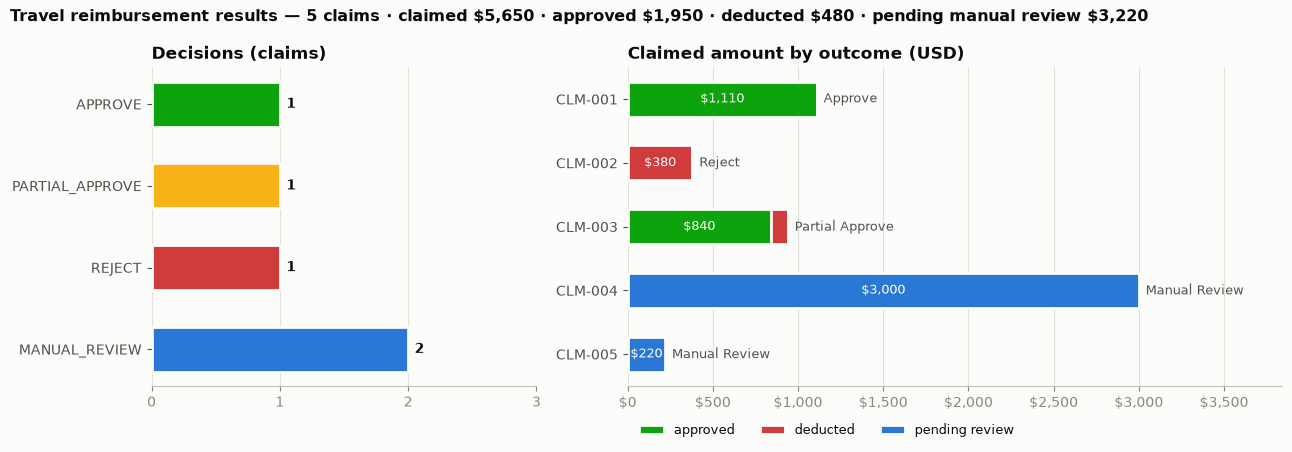

Saved dashboard image → UI SS_1.png


In [78]:
DECISIONS = ["APPROVE", "PARTIAL_APPROVE", "REJECT", "MANUAL_REVIEW"]
DECISION_COLORS = {"APPROVE": "#0ca30c", "PARTIAL_APPROVE": "#fab219", "REJECT": "#d03b3b",
                   "MANUAL_REVIEW": "#2a78d6"}
AMOUNT_COLORS = {"approved": "#0ca30c", "deducted": "#d03b3b", "pending review": "#2a78d6"}
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"

summary = pd.DataFrame(results)
summary["claimed"] = summary["claim_id"].map(lambda cid: CLAIM_REGISTRY[cid].total_claimed)
summary["pending_review"] = summary.apply(lambda r: r["claimed"] if r["decision"] == "MANUAL_REVIEW" else 0.0, axis=1)
summary["#missing_docs"] = summary["missing_docs"].map(len)
table = summary[["claim_id", "decision", "claimed", "approved_amount", "deducted_amount", "pending_review",
                 "confidence", "#missing_docs", "policy_refs"]]
display(table.style.format({"claimed": "${:,.2f}", "approved_amount": "${:,.2f}", "deducted_amount": "${:,.2f}",
                            "pending_review": "${:,.2f}", "confidence": "{:.2f}",
                            "policy_refs": lambda v: ", ".join(v)}).hide(axis="index"))


def draw_dashboard(summary: pd.DataFrame, path: str = "UI SS_1.png"):
    plt.rcParams.update({"text.parse_math": False, "font.size": 10, "axes.edgecolor": AXIS, "axes.labelcolor": INK_2,
                         "xtick.color": MUTED, "ytick.color": INK_2, "text.color": INK})
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.7]},
                                   facecolor=SURFACE)
    for ax in (ax1, ax2):
        ax.set_facecolor(SURFACE)
        ax.spines[["top", "right", "left"]].set_visible(False)
        ax.grid(axis="x", color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)

    # Panel 1 — decision breakdown
    counts = summary["decision"].value_counts().reindex(DECISIONS, fill_value=0)
    ax1.barh(DECISIONS[::-1], counts[DECISIONS[::-1]], color=[DECISION_COLORS[d] for d in DECISIONS[::-1]],
             height=0.55, edgecolor=SURFACE, linewidth=2)
    for y, d in enumerate(DECISIONS[::-1]):
        ax1.text(counts[d] + 0.05, y, str(counts[d]), va="center", color=INK, fontweight="bold")
    ax1.set_xlim(0, max(counts.max() + 0.8, 3))
    ax1.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax1.set_title("Decisions (claims)", loc="left", fontweight="bold", color=INK)

    # Panel 2 — where the money went, per claim
    s = summary.iloc[::-1]
    left = [0.0] * len(s)
    for label, col in [("approved", "approved_amount"), ("deducted", "deducted_amount"),
                       ("pending review", "pending_review")]:
        vals = s[col].tolist()
        ax2.barh(s["claim_id"], vals, left=left, color=AMOUNT_COLORS[label], height=0.55,
                 edgecolor=SURFACE, linewidth=2, label=label)
        for y, (v, l0) in enumerate(zip(vals, left)):
            if v >= 150:
                ax2.text(l0 + v / 2, y, f"${v:,.0f}", ha="center", va="center", color="#ffffff", fontsize=9)
        left = [a + b for a, b in zip(left, vals)]
    for y, (cid, dec) in enumerate(zip(s["claim_id"], s["decision"])):
        ax2.text(left[y] + 40, y, dec.replace("_", " ").title(), va="center", color=INK_2, fontsize=9)
    ax2.set_xlim(0, max(left) * 1.28)
    ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
    ax2.set_title("Claimed amount by outcome (USD)", loc="left", fontweight="bold", color=INK)
    ax2.legend(loc="upper left", frameon=False, ncol=3, bbox_to_anchor=(0, -0.08), fontsize=9)

    tot = summary[["claimed", "approved_amount", "deducted_amount", "pending_review"]].sum()
    fig.suptitle(f"Travel reimbursement results — {len(summary)} claims · claimed ${tot['claimed']:,.0f} · "
                 f"approved ${tot['approved_amount']:,.0f} · deducted ${tot['deducted_amount']:,.0f} · "
                 f"pending manual review ${tot['pending_review']:,.0f}",
                 x=0.01, ha="left", fontsize=11.5, fontweight="bold", color=INK)
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight", facecolor=SURFACE)
    plt.show()
    print(f"Saved dashboard image → {path}")


draw_dashboard(summary)

### Interactive panel
* **Sample claims** — view the stored result for any Appendix B claim, or re-run the agent live.
* **New claim (form)** — enter trip details and line items, then click *Evaluate*.
* **Paste JSON** — evaluate any claim JSON in the same schema as the samples.

New claims are evaluated by the same agent + guardrail; they do not change the five results above.

In [79]:
import time
from html import escape

import ipywidgets as w


def decision_card_html(r: dict) -> str:
    color = DECISION_COLORS[r["decision"]]
    badge_ink = "#0b0b0b" if r["decision"] == "PARTIAL_APPROVE" else "#ffffff"
    claimed = CLAIM_REGISTRY[r["claim_id"]].total_claimed
    chips = " ".join(f"<span style='border:1px solid {AXIS};border-radius:10px;padding:1px 8px;"
                     f"margin-right:4px;font-size:12px'>{x}</span>" for x in r["policy_refs"])
    missing = ("<ul style='margin:4px 0 0 18px'>" + "".join(f"<li>{m}</li>" for m in r["missing_docs"]) + "</ul>"
               if r["missing_docs"] else "<span style='color:#52514e'>none</span>")
    return f"""
    <div style="font-family:system-ui,sans-serif;border:1px solid {GRID};border-left:6px solid {color};
                border-radius:8px;padding:14px 18px;background:{SURFACE};color:{INK};max-width:820px">
      <div style="display:flex;align-items:center;gap:12px">
        <b style="font-size:16px">{r['claim_id']}</b>
        <span style="background:{color};color:{badge_ink};border-radius:4px;padding:2px 10px;font-weight:600">
          {r['decision'].replace('_', ' ')}</span>
        <span style="color:{INK_2}">confidence {r['confidence']:.2f}</span>
      </div>
      <div style="display:flex;gap:28px;margin:12px 0">
        <div><div style="color:{INK_2};font-size:12px">Claimed</div><b>${claimed:,.2f}</b></div>
        <div><div style="color:{INK_2};font-size:12px">Approved</div><b>${r['approved_amount']:,.2f}</b></div>
        <div><div style="color:{INK_2};font-size:12px">Deducted</div><b>${r['deducted_amount']:,.2f}</b></div>
      </div>
      <div style="margin-bottom:8px">{r['explanation']}</div>
      <div style="margin-bottom:6px"><span style="color:{INK_2}">Missing docs:</span> {missing}</div>
      <div style="margin-bottom:6px"><span style="color:{INK_2}">Policy refs:</span> {chips}</div>
      <div><span style="color:{INK_2}">Tools used:</span> {', '.join(r['tools_used']) or '—'}</div>
    </div>"""


def trace_html(claim_id: str) -> str:
    steps = AUDIT.get(claim_id, {}).get("trace", [])
    items = "".join(f"<li><code>{s['tool']}</code> {json.dumps(s['args'])}</li>" for s in steps)
    return (f"<details style='margin-top:6px;font-family:system-ui'><summary>Agent tool-call trace "
            f"({len(steps)} calls)</summary><ol>{items}</ol></details>")


# ---- Result areas are plain HTML widgets: each update replaces `.value` in one atomic step, so a result can never
# be rendered twice. (ipywidgets' Output widget can duplicate content in VS Code when it is cleared and refilled.)
def result_area() -> w.HTML:
    return w.HTML(value="")


def set_text(out: w.HTML, text: str):
    out.value = f"<pre style='font-family:system-ui;margin:6px 0'>{escape(text)}</pre>"


def set_html(out: w.HTML, html: str):
    out.value = html


def result_html(r: dict) -> str:
    return decision_card_html(r) + trace_html(r["claim_id"])


def show_result(out: w.HTML, r: dict):
    set_html(out, result_html(r))


def on_click_once(btn: w.Button, out: w.HTML, action):
    """Attach `action` so that one click = one agent run.

    The button is disabled while the agent runs, and clicks that arrive while it is busy - or that were queued
    during the run (double-clicks) - are ignored. Errors are shown in the output instead of being lost.
    """
    state = {"busy": False, "done_at": 0.0}
    label = btn.description

    def handler(_):
        if state["busy"] or time.monotonic() - state["done_at"] < 1.0:
            return
        state["busy"], btn.disabled, btn.description = True, True, "Running…"
        try:
            action()
        except Exception as e:
            set_text(out, f"Error: {type(e).__name__}: {e}")
        finally:
            state["busy"], state["done_at"] = False, time.monotonic()
            btn.disabled, btn.description = False, label

    btn.on_click(handler)


# ---- Tab 1: sample claims
sample_dd = w.Dropdown(options=[c.claim_id for c in CLAIMS], description="Claim:")
btn_show = w.Button(description="Show result", button_style="info", icon="eye")
btn_rerun = w.Button(description="Re-run agent", icon="refresh")
out_samples = result_area()


def _show_stored():
    show_result(out_samples, next(r for r in results if r["claim_id"] == sample_dd.value))


def _rerun():
    set_text(out_samples, f"Running agent on {sample_dd.value} ...")
    show_result(out_samples, evaluate_claim(CLAIM_REGISTRY[sample_dd.value]))


on_click_once(btn_show, out_samples, _show_stored)
on_click_once(btn_rerun, out_samples, _rerun)
tab_samples = w.VBox([w.HBox([sample_dd, btn_show, btn_rerun]), out_samples])

# ---- Tab 2: form intake
CATEGORY_OPTIONS = ELIGIBLE_CATEGORIES + INELIGIBLE_CATEGORIES + ["other"]
f_employee = w.Text(value="Test User", description="Employee:")
f_purpose = w.Text(value="Customer workshop (business)", description="Purpose:", layout=w.Layout(width="420px"))
f_start = w.DatePicker(value=date(2026, 6, 10), description="Trip start:")
f_end = w.DatePicker(value=date(2026, 6, 11), description="Trip end:")
f_sub = w.DatePicker(value=date(2026, 6, 15), description="Submitted:")
item_rows = w.VBox([])


def add_item_row(_=None, category="meals", desc="Meals, 2 days", amount=120.0, receipt=True):
    row = w.HBox([w.Dropdown(options=CATEGORY_OPTIONS, value=category, layout=w.Layout(width="170px")),
                  w.Text(value=desc, placeholder="description", layout=w.Layout(width="300px")),
                  w.BoundedFloatText(value=amount, min=0, max=1e6, step=1, layout=w.Layout(width="110px")),
                  w.Checkbox(value=receipt, description="receipt", indent=False)])
    item_rows.children = item_rows.children + (row,)


add_item_row(category="lodging", desc="Hotel, 1 night", amount=210.0)
add_item_row()
btn_add = w.Button(description="+ Add line")
btn_add.on_click(add_item_row)
btn_eval_form = w.Button(description="Evaluate", button_style="success", icon="check")
out_form = result_area()
_form_counter = {"n": 0}


def _eval_form():
    try:
        claim = Claim(claim_id=f"FORM-{_form_counter['n'] + 1:03d}", employee=f_employee.value,
                      purpose=f_purpose.value, trip_start=f_start.value, trip_end=f_end.value, submitted=f_sub.value,
                      items=[LineItem(category=r.children[0].value, description=r.children[1].value,
                                      amount=r.children[2].value, receipt_attached=r.children[3].value)
                             for r in item_rows.children])
    except Exception as e:
        set_text(out_form, f"Invalid claim: {e}")
        return
    _form_counter["n"] += 1
    set_text(out_form, f"Running agent on {claim.claim_id} ...")
    show_result(out_form, evaluate_claim(claim))


on_click_once(btn_eval_form, out_form, _eval_form)
tab_form = w.VBox([w.HBox([f_employee, f_purpose]), w.HBox([f_start, f_end, f_sub]),
                   w.HTML("<b>Line items</b> (category · description · amount USD · receipt attached)"),
                   item_rows, w.HBox([btn_add, btn_eval_form]), out_form])

# ---- Tab 3: paste JSON
json_template = CLAIM_REGISTRY["CLM-003"].model_dump(mode="json") | {"claim_id": "JSON-001", "employee": "Test User"}
json_box = w.Textarea(value=json.dumps(json_template, indent=2), layout=w.Layout(width="720px", height="260px"))
btn_eval_json = w.Button(description="Evaluate JSON", button_style="success", icon="check")
out_json = result_area()


def _eval_json():
    try:
        claims = load_claims_from_json(json_box.value)
    except Exception as e:
        set_text(out_json, f"Invalid claim JSON: {e}")
        return
    set_text(out_json, f"Running agent on {', '.join(c.claim_id for c in claims)} ...")
    set_html(out_json, "".join(result_html(evaluate_claim(c)) for c in claims))


on_click_once(btn_eval_json, out_json, _eval_json)
tab_json = w.VBox([json_box, btn_eval_json, out_json])

panel = w.Tab(children=[tab_samples, tab_form, tab_json])
for i, title in enumerate(["Sample claims", "New claim (form)", "Paste JSON"]):
    panel.set_title(i, title)
display(panel)
show_result(out_samples, results[0])

## Design Notes & Reasoning

### Architecture
`Claim (JSON/CSV/form) → Pydantic intake → LangChain create_agent (OpenRouter model) ⇄ 6 deterministic tools →
guardrail/validator → strict JSON → dashboard`. See `design_flow.md` in the repo for the diagram.

### Why this split of responsibilities
* **Deterministic tools for anything numeric or rule-based.** Per-diem caps, receipt rules, tiers and dates are
  simple and unambiguous; computing them in Python makes amounts exact, testable and identical across runs.
  LLMs are unreliable at arithmetic, so the prompt forbids it.
* **LLM for orchestration, synthesis and communication.** The agent decides which policy sections to retrieve and
  which checks are relevant, reconciles tool outputs (e.g. a claim that is both over-cap and missing a receipt),
  decides how to present it and writes a reviewer-ready explanation with a calibrated confidence. It can also
  escalate to Manual Review when it sees ambiguity the rules don't encode.
* **Guardrail as a safety net, not a replacement.** It only *raises* caution (hard triggers → Manual Review),
  corrects amounts to tool values, filters hallucinated rule ids, and falls back to Manual Review on any failure.
  Every intervention is written into the explanation and lowers confidence, so it is visible to reviewers.
* **Rule-id lookup over vector RAG.** ~15 short rules with stable ids: exact keyword/id retrieval is more precise,
  cheaper and gives verifiable citations. RAG becomes worthwhile once the policy is long or unstructured.

### Why each case is routed the way it is
| Claim | Outcome | Reasoning |
|---|---|---|
| CLM-001 | APPROVE | All eligible; lodging $180/night ≤ $200, meals $60/day ≤ $75; receipts attached; $1,110 → manager tier (approvable); submitted on time. |
| CLM-002 | REJECT | Spa and minibar are ineligible (POL-CAT-02); nothing reimbursable; the purpose ("weekend hotel stay") states no business reason either. |
| CLM-003 | PARTIAL_APPROVE | Lodging $250/night vs $200 cap → $100 deducted (POL-PD-02); everything else compliant; $840 reimbursable. |
| CLM-004 | MANUAL_REVIEW | Business-class airfare is a policy exception that may be pre-approved (POL-AIR-01, never auto-deducted); lodging receipt missing (POL-RCT-02); $3,000 exceeds the agent's authority (POL-APR-03); and "3 nights" conflicts with 16–18 June (2 nights). |
| CLM-005 | MANUAL_REVIEW | $220 meal with no receipt (POL-RCT-02). Also a client dinner for 4 against a per-employee $75/day cap — the policy doesn't say how hosting is treated, so deducting $145 could be wrong. A reviewer should request the receipt and attendee list. |

### Assumptions
* **Manual Review amounts are 0 / 0** — nothing is approved or deducted until a human decides; provisional figures
  (e.g. CLM-005: $75 approved / $145 over cap) are given in the explanation.
* Per-diem quantity comes from the line description ("2 nights", "3 days"), falling back to the trip dates
  (nights = end − start, days = end − start + 1). Claiming *more* units than the dates allow is flagged as a conflict.
* Line items have no individual dates, so the **trip start date** is used as the expense date for the 30-day rule
  (the most conservative choice).
* Approval tier is evaluated on *allowed + pending-review* amounts (after per-diem deductions, per POL-APR).
* A REJECT is only issued when **everything** is ineligible; a mix of eligible and ineligible items is
  PARTIAL_APPROVE with the ineligible items deducted.
* Each line is capped individually; the sample claims have at most one line per capped category.

### Trade-offs
* The guardrail makes the final decision largely rule-determined, which costs some "LLM autonomy" but buys
  reliability and auditability — the right trade for money decisions. The LLM still drives tool use, can escalate
  to Manual Review, and owns the explanation and confidence.


## Assumptions and limitations
* **Known gaps:** no OCR/receipt parsing (receipt presence is a boolean); no duplicate-claim detection; no
  currency conversion (USD only); per-day caps aren't aggregated across multiple lines of the same category or day;
  
* **Simplifications:** the policy is parsed with simple rules tuned to Policy's format; keyword lookup would need
  extending for new vocabulary; confidence is LLM-estimated and then capped by the guardrail, not statistically calibrated.

### What I would improve next
1. Receipt OCR/metadata extraction (date, vendor, amount) and cross-checking against claimed lines.
2. Duplicate detector across claims (same employee / vendor / date / amount).
3. Per-day aggregation of caps using line-item dates; multi-currency support.
4. An evaluation set with expected decisions, run in CI to catch prompt or model regressions; LangSmith tracing.
5. Human-in-the-loop: let a reviewer resolve Manual Review cases (e.g. attach a receipt or pre-approval)


## Final structured results
One object per sample claims, with exactly the fields `claim_id, decision, approved_amount, deducted_amount,
missing_docs, policy_refs, confidence, explanation, tools_used`.

In [80]:
assert [r["claim_id"] for r in results] == [c.claim_id for c in CLAIMS]
for r in results:
    ClaimResult.model_validate(r)
    assert list(r) == RESULT_KEYS

print(json.dumps(results, indent=2))

[
  {
    "claim_id": "CLM-001",
    "decision": "APPROVE",
    "approved_amount": 1110.0,
    "deducted_amount": 0.0,
    "missing_docs": [],
    "policy_refs": [
      "POL-CAT-01",
      "POL-PD-01",
      "POL-PD-02",
      "POL-RCT-01",
      "POL-APR-02",
      "POL-TIME-01"
    ],
    "confidence": 0.97,
    "explanation": "All line items are eligible under POL-CAT-01, lodging and meals are within per\u2011diem caps per POL-PD-02 and POL-PD-01, required receipts are attached per POL-RCT-01, the claim was submitted within 30 days per POL-TIME-01, and the total reimbursable amount $1,110 falls in the Manager approval tier per POL-APR-02. No policy flags were raised.",
    "tools_used": [
      "lookup_policy",
      "check_eligibility",
      "check_per_diem_limits",
      "check_receipts",
      "check_timeliness",
      "check_approval_threshold"
    ]
  },
  {
    "claim_id": "CLM-002",
    "decision": "REJECT",
    "approved_amount": 0.0,
    "deducted_amount": 380.0,
    "mis